# Example of the aitlas toolbox in the context of semantic segmentation

The SatlasPretrain dataset being very large, this notebook showcases an example on a subset of the dataset. The dataset can be used for image classification or semantic segmentation. We here consider the semantic segmentation task using the static labels. 

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import SatlasPretrainSemanticSegmentationDataset
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
from aitlas.utils import image_loader
import math
import matplotlib.pyplot as plt

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/satlaspretrain_semantic_segmentation/",
    "tile_list": "./data/satlaspretrain_semantic_segmentation/tile_list.txt", # created using the create_tile_list function
}
dataset = SatlasPretrainSemanticSegmentationDataset(dataset_config)
print(len(dataset))

43209


## Show images from the dataset

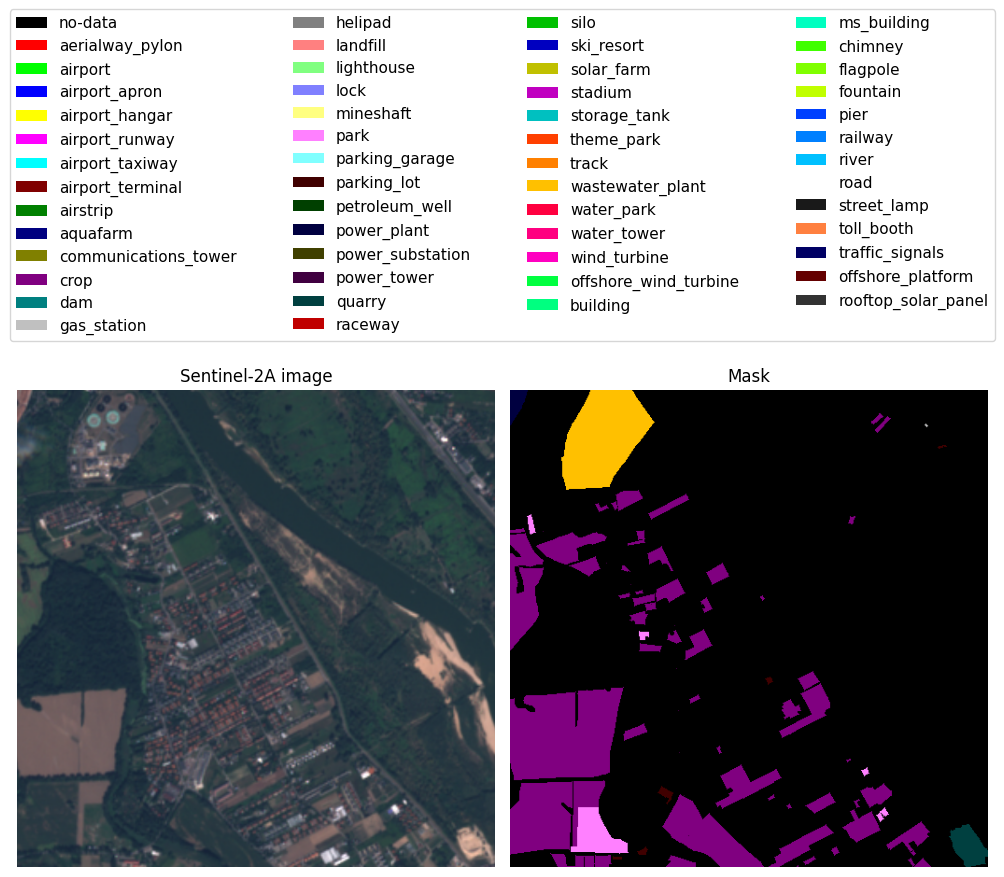

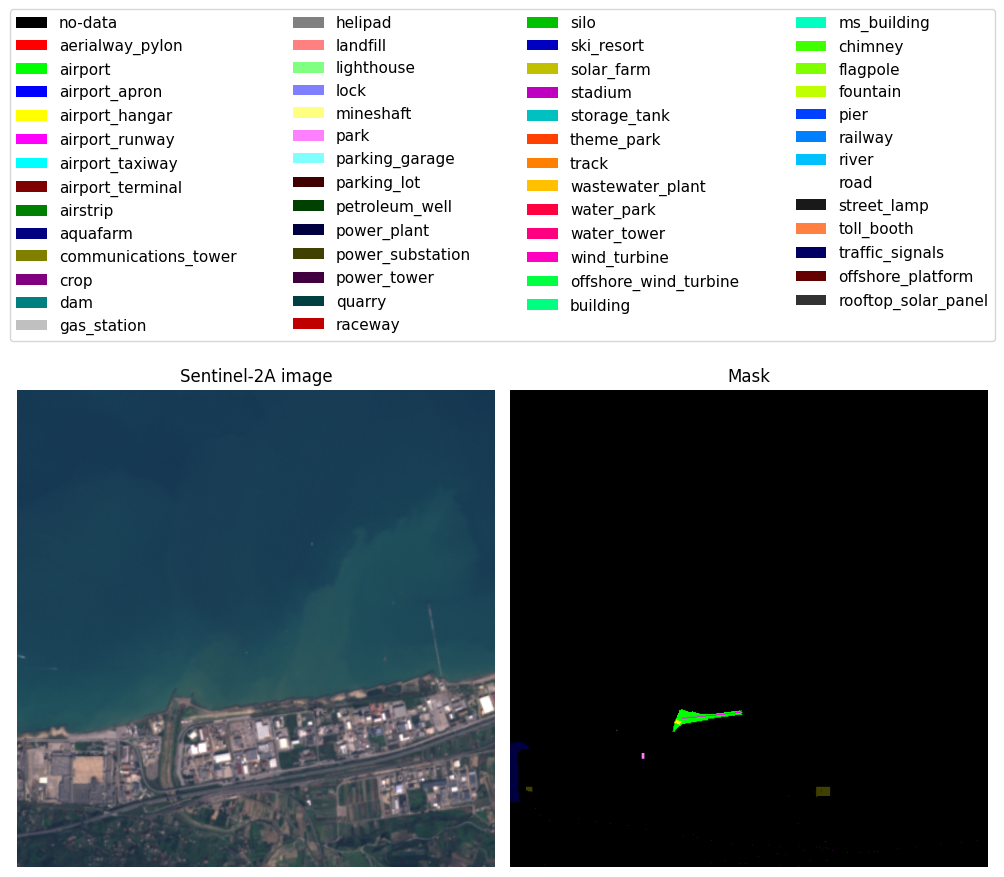

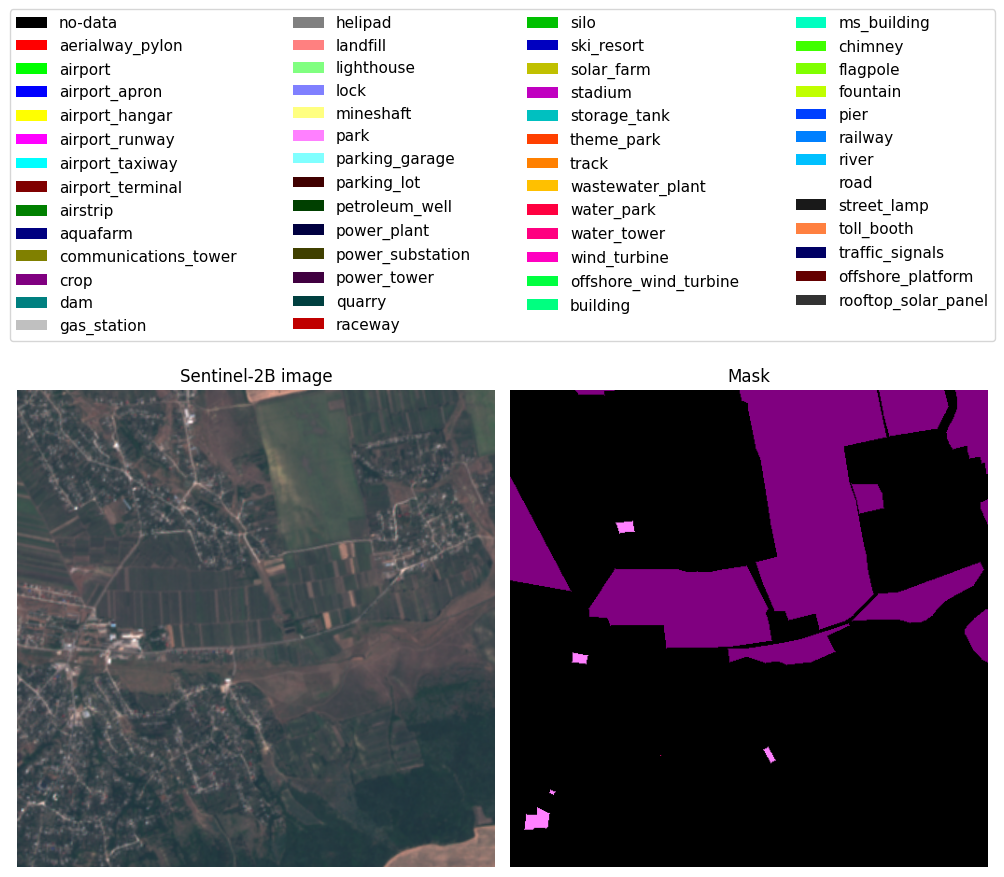

In [10]:
fig1 = dataset.show_image(100)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(3000)

## Inspect the data

In [6]:
dataset.data_distribution_table()

,Number of pixels
no-data,9.954488e+09
aerialway_pylon,1.405000e+03
airport,1.956332e+07
airport_apron,8.875130e+05
airport_hangar,3.406600e+04
airport_runway,3.982280e+05
airport_taxiway,3.442250e+05
airport_terminal,2.771900e+04
airstrip,1.630500e+04
aquafarm,1.548452e+06


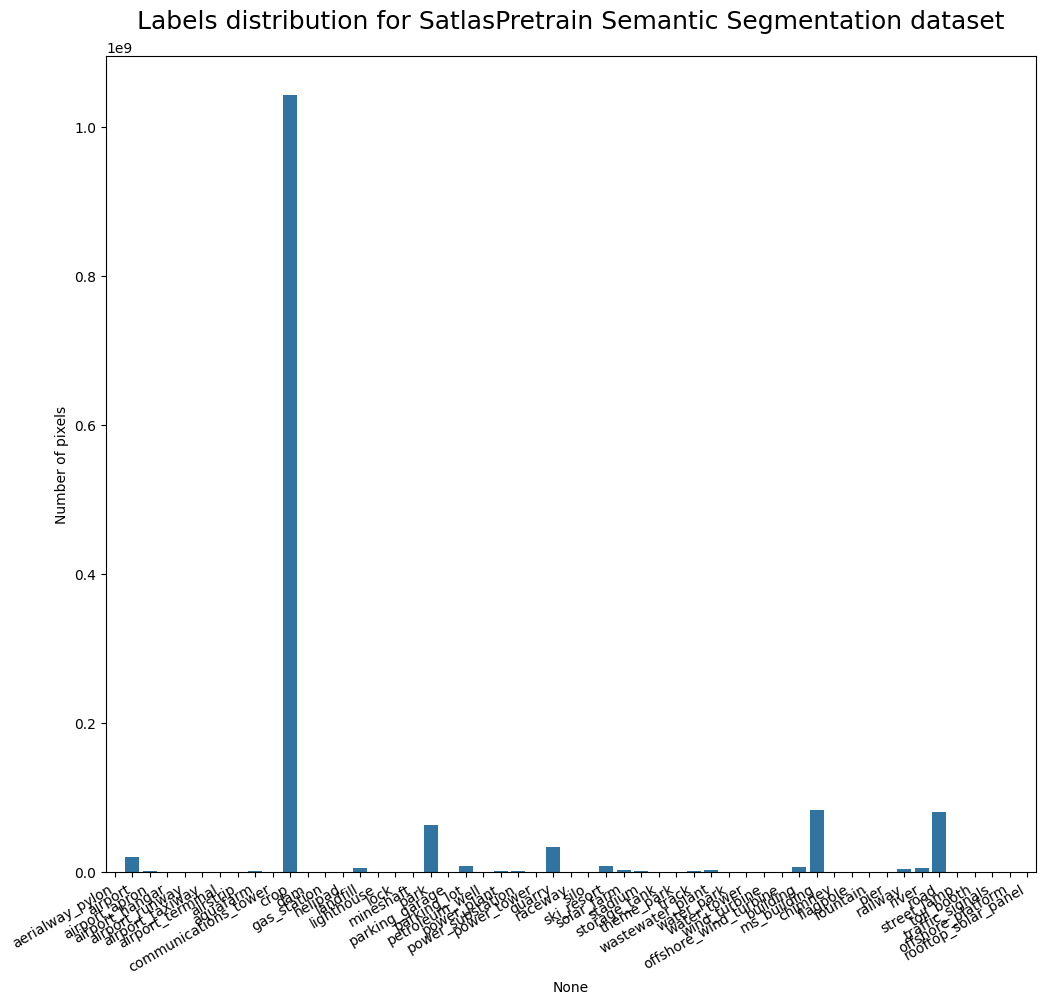

In [7]:
fig = dataset.data_distribution_barchart()

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/satlaspretrain_semantic_segmentation",
    "tile_list": "./data/satlaspretrain_semantic_segmentation/tile_list.txt",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = SatlasPretrainSemanticSegmentationDataset(train_dataset_config)
len(train_dataset)

34390

## Setup and create the model for training

In [ ]:
epochs = 5
model_directory = "./data/experiments/satlaspretrain_semantic_segmentation"
model_config = {
    "num_classes": 54, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-10 14:20:27,736 INFO Starting training.
training: 100%|██████████| 2150/2150 [33:26<00:00,  1.07it/s]
2025-11-10 14:53:54,281 INFO epoch: 1, time: 2006, loss:  0.24282
testing on train set: 100%|██████████| 2150/2150 [32:33<00:00,  1.10it/s] 
2025-11-10 15:26:29,699 INFO IOU:0.7642545010239362, IOU mean:0.015496495097730078, IOU per Class:[8.36805200e-01 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 5.53551871e-06
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/satlaspretrain_semantic_segmentation",
    "tile_list": "./data/satlaspretrain_semantic_segmentation/tile_list.txt",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = SatlasPretrainSemanticSegmentationDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/satlaspretrain_semantic_segmentation/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

3899


2025-11-11 07:45:07,611 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/satlaspretrain_semantic_segmentation/checkpoint.pth.tar
2025-11-11 07:45:08,188 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/satlaspretrain_semantic_segmentation/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 975/975 [04:10<00:00,  3.89it/s]


[{'IOU': 0.7649978412991547,
  'IOU mean': 0.015482692401982337,
  'IOU per Class': array([0.83606539, 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        ])}]

## Predictions

In [10]:
'''
The predictions will give 54 masks (one per class). 
This function rearranges the figure to make it more readable.
'''
def rearrange_figure_to_grid(fig, cols=8):
    original_axes = fig.axes
    num_plots = len(original_axes)
    rows = math.ceil(num_plots / cols)

    # Create a new figure
    new_fig, new_axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))
    new_axes = new_axes.flatten()

    for i, old_ax in enumerate(original_axes):
        # Extract the image and title
        im = old_ax.images[0] if old_ax.images else None
        title = old_ax.get_title()

        # Copy to new axis
        if im:
            new_axes[i].imshow(im.get_array(), cmap=im.get_cmap())
            new_axes[i].set_title(title, fontsize=13)
        new_axes[i].axis('off')

    # Turn off any unused subplots
    for j in range(i + 1, len(new_axes)):
        new_axes[j].axis('off')

    plt.tight_layout()
    return new_fig

2025-11-11 07:55:22,790 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/satlaspretrain_semantic_segmentation/checkpoint.pth.tar
2025-11-11 07:55:23,259 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/satlaspretrain_semantic_segmentation/checkpoint.pth.tar at epoch 6


The amount of images for testing is 1294


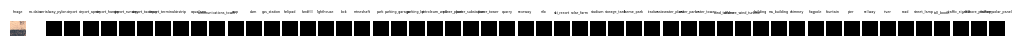

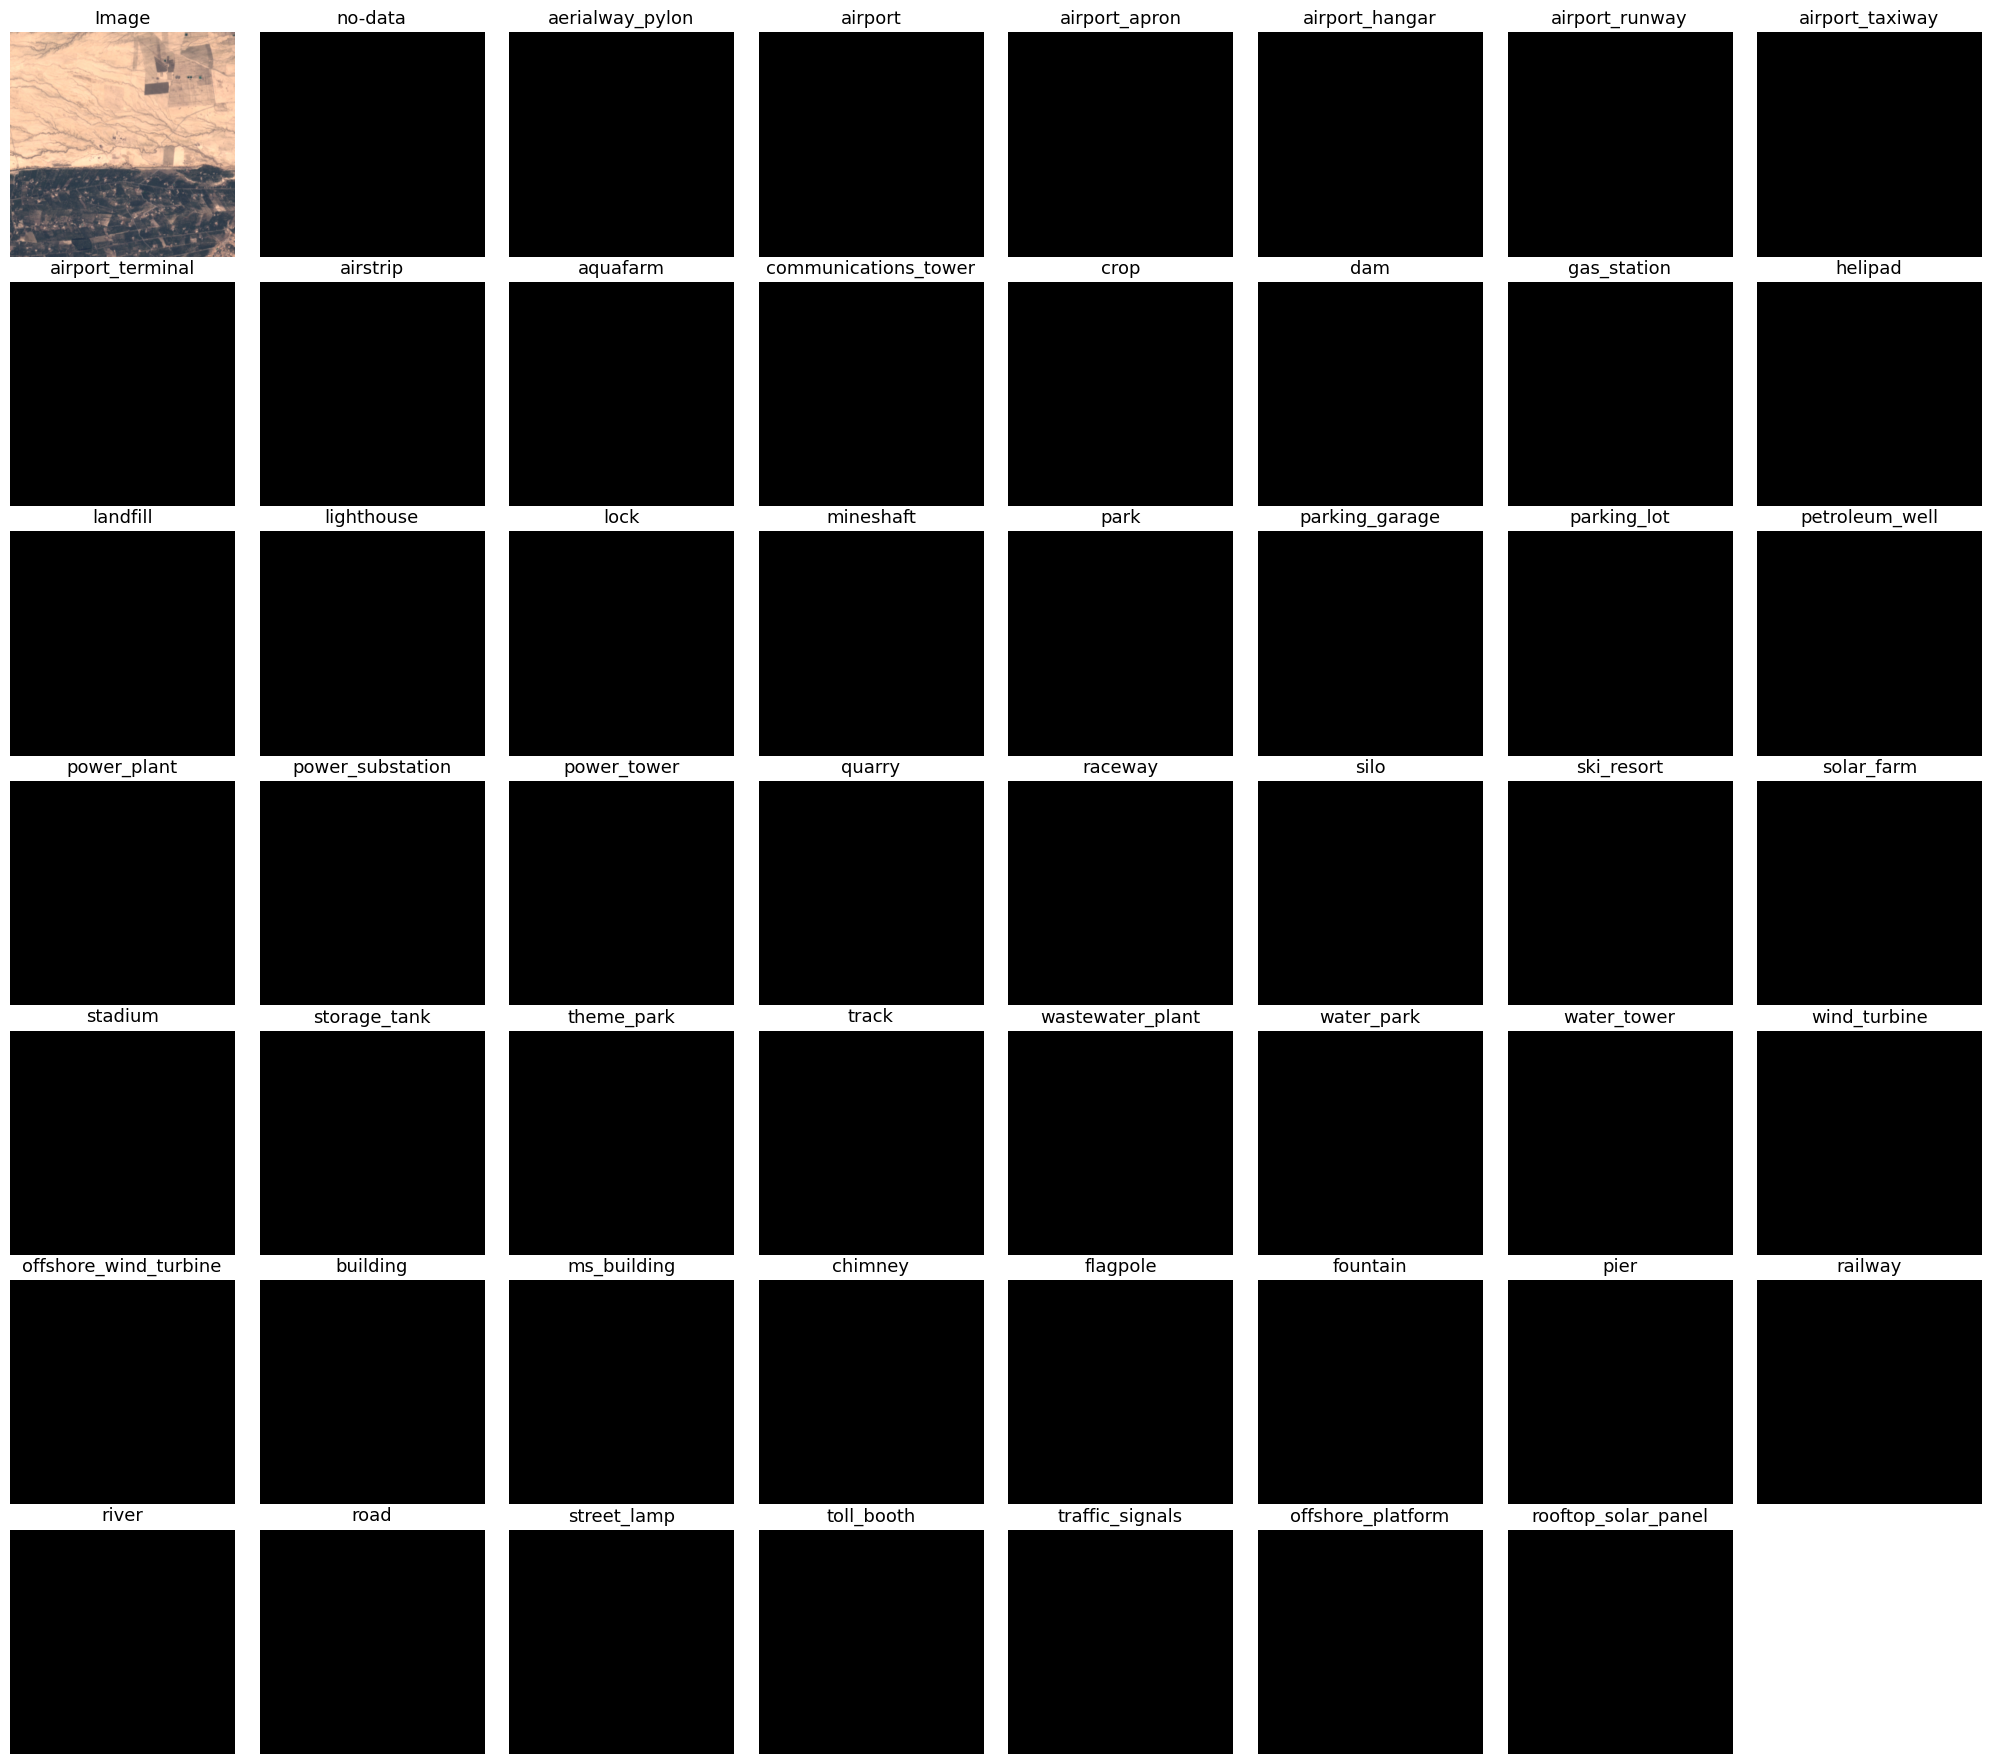

In [ ]:
model_path = "./data/experiments/satlaspretrain_semantic_segmentation/checkpoint.pth.tar"
labels = ["no-data","aerialway_pylon","airport","airport_apron","airport_hangar","airport_runway","airport_taxiway","airport_terminal",
           "airstrip","aquafarm","communications_tower","crop","dam","gas_station","helipad","landfill","lighthouse","lock",
           "mineshaft","park","parking_garage","parking_lot","petroleum_well","power_plant","power_substation","power_tower",
           "quarry","raceway","silo","ski_resort","solar_farm","stadium","storage_tank","theme_park","track","wastewater_plant",
           "water_park","water_tower","wind_turbine","offshore_wind_turbine","building","ms_building","chimney","flagpole",
           "fountain","pier","railway","river","road","street_lamp","toll_booth","traffic_signals","offshore_platform",
           "rooftop_solar_panel"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 2})

test_dataset_config = {
    "data_dir": "./data/satlaspretrain_semantic_segmentation",
    "tile_list": "./data/satlaspretrain_semantic_segmentation/tile_list.txt",
    "mode": "test",
}

test_dataset = SatlasPretrainSemanticSegmentationDataset(test_dataset_config)
print(f'The amount of images for testing is {len(test_dataset)}')

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)
new_fig = rearrange_figure_to_grid(fig, cols=8)
new_fig.show()